# EEG Cognitive Fatigue Detection
## Notebook 1: Data Exploration

**Project:** EEG-Based Cognitive Fatigue Detection Across Age Groups  
**Dataset:** OpenNeuro ds005385 — Resting-state EEG before/after cognitive task (608 subjects)  
**Reference:** Yang et al. (2025) Brain Sciences

### Objectives
1. Explore dataset structure and participants demographics
2. Understand BIDS file format
3. Identify age group distribution for analysis

In [1]:
# Cell 1: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs('outputs', exist_ok=True)

print("Libraries loaded successfully")

Libraries loaded successfully


In [2]:
# Cell 2: Load participants data
participants = pd.read_csv('Dataset/participants.tsv', sep='\t')

print(f"Total participants: {len(participants)}")
print(f"\nColumns: {participants.columns.tolist()}")
print(f"\nFirst 5 rows:")
participants.head()

Total participants: 608

Columns: ['participant_id', 'sex', 'age', 'handedness', 'session1', 'late_ses1', 'session2', 'late_ses2']

First 5 rows:


,participant_id,sex,age,handedness,session1,late_ses1,session2,late_ses2
0,sub-001,F,60,right,yes,0,yes,0.0
1,sub-002,M,67,right,yes,0,no,NaN
2,sub-003,F,44,right,yes,0,no,NaN
3,sub-004,F,24,right,yes,0,no,NaN
4,sub-005,F,48,right,yes,0,yes,5.0


In [3]:
# Cell 3: Age group assignment and basic statistics
def assign_age_group(age):
    if age <= 34:
        return 'Young (20-34)'
    elif age <= 50:
        return 'Middle (35-50)'
    else:
        return 'Older (51-70)'

participants['age_group'] = participants['age'].apply(assign_age_group)

print("=== Age Statistics ===")
print(participants['age'].describe())

print("\n=== Age Group Distribution ===")
print(participants['age_group'].value_counts().sort_index())

print("\n=== Sex Distribution ===")
print(participants['sex'].value_counts())

print("\n=== Session 2 (Follow-up) Availability ===")
print(participants['session2'].value_counts())

=== Age Statistics ===
count    608.000000
mean      44.067434
std       14.511839
min       20.000000
25%       30.000000
50%       46.000000
75%       56.000000
max       70.000000
Name: age, dtype: float64

=== Age Group Distribution ===
age_group
Middle (35-50)    175
Older (51-70)     230
Young (20-34)     203
Name: count, dtype: int64

=== Sex Distribution ===
sex
F    376
M    232
Name: count, dtype: int64

=== Session 2 (Follow-up) Availability ===
session2
no     400
yes    208
Name: count, dtype: int64


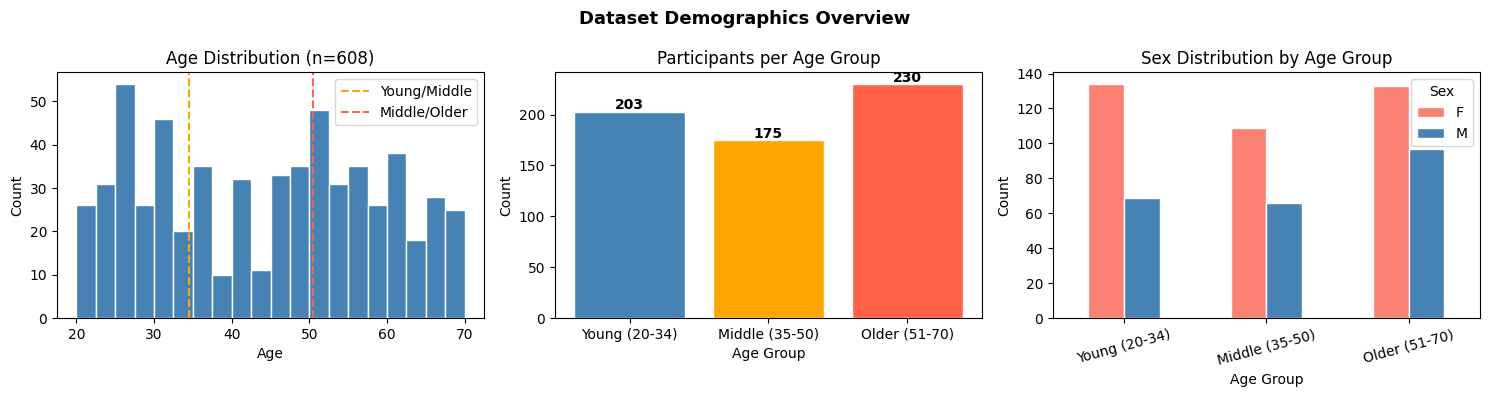

Done


In [4]:
# Cell 4: Visualize age distribution
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

order = ['Young (20-34)', 'Middle (35-50)', 'Older (51-70)']
colors_order = ['steelblue', 'orange', 'tomato']

# Plot 1: Age histogram
axes[0].hist(participants['age'], bins=20, color='steelblue', edgecolor='white')
axes[0].axvline(x=34.5, color='orange', linestyle='--', label='Young/Middle')
axes[0].axvline(x=50.5, color='tomato', linestyle='--', label='Middle/Older')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Count')
axes[0].set_title('Age Distribution (n=608)')
axes[0].legend()

# Plot 2: Age group bar chart — เรียงตามอายุ
order = ['Young (20-34)', 'Middle (35-50)', 'Older (51-70)']
age_counts = participants['age_group'].value_counts().reindex(order)
bars = axes[1].bar(age_counts.index, age_counts.values,
                   color=colors_order, edgecolor='white')
axes[1].set_xlabel('Age Group')
axes[1].set_ylabel('Count')
axes[1].set_title('Participants per Age Group')
for bar, val in zip(bars, age_counts.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 2,
                str(val), ha='center', fontweight='bold')

# Plot 3: Sex distribution per age group — เรียงตามอายุ
sex_age = participants.groupby(['age_group', 'sex']).size().unstack().reindex(order)
sex_age.plot(kind='bar', ax=axes[2], color=['salmon', 'steelblue'],
             edgecolor='white', rot=15)
axes[2].set_xlabel('Age Group')
axes[2].set_ylabel('Count')
axes[2].set_title('Sex Distribution by Age Group')
axes[2].legend(title='Sex')

plt.suptitle('Dataset Demographics Overview', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/01_demographics.png', dpi=150, bbox_inches='tight')
plt.show()
print("Done")

In [5]:
# Cell 5: Explore EEG file structure
sub_path = 'Dataset/sub-001'
print("=== File structure of sub-001 ===")
for root, dirs, files in os.walk(sub_path):
    level = root.replace(sub_path, '').count(os.sep)
    indent = '  ' * level
    print(f"{indent}{os.path.basename(root)}/")
    for file in sorted(files):
        subindent = '  ' * (level + 1)
        print(f"{subindent}{file}")

=== File structure of sub-001 ===
sub-001/
  sub-001_sessions.json
  sub-001_sessions.tsv
  ses-2/
    eeg/
      sub-001_ses-2_task-EyesClosed_acq-post_channels.tsv
      sub-001_ses-2_task-EyesClosed_acq-post_eeg.edf
      sub-001_ses-2_task-EyesClosed_acq-post_eeg.json
      sub-001_ses-2_task-EyesClosed_acq-post_events.json
      sub-001_ses-2_task-EyesClosed_acq-post_events.tsv
      sub-001_ses-2_task-EyesClosed_acq-pre_channels.tsv
      sub-001_ses-2_task-EyesClosed_acq-pre_eeg.edf
      sub-001_ses-2_task-EyesClosed_acq-pre_eeg.json
      sub-001_ses-2_task-EyesClosed_acq-pre_events.json
      sub-001_ses-2_task-EyesClosed_acq-pre_events.tsv
      sub-001_ses-2_task-EyesOpen_acq-post_channels.tsv
      sub-001_ses-2_task-EyesOpen_acq-post_eeg.edf
      sub-001_ses-2_task-EyesOpen_acq-post_eeg.json
      sub-001_ses-2_task-EyesOpen_acq-post_events.json
      sub-001_ses-2_task-EyesOpen_acq-post_events.tsv
      sub-001_ses-2_task-EyesOpen_acq-pre_channels.tsv
      sub-001_ses-

In [6]:
# Cell 6: Check late_ses1 — number of late triggers (data quality flag)
print("=== BIDS Naming Convention ===")
print("sub-{id}_ses-{session}_task-{task}_acq-{condition}_eeg.edf")
print()
print("Components:")
print("  ses-1     = baseline measurement")
print("  ses-2     = follow-up (~5 years later, 208 subjects only)")
print("  task      = EyesOpen | EyesClosed")
print("  acq       = pre (before 2hr task) | post (after 2hr task)")
print()
print("=== Files per subject per session ===")
print("  4 EEG recordings:")
print("  1. EyesOpen_pre   -> label 0 (pre-task)")
print("  2. EyesClosed_pre -> label 0 (pre-task)")
print("  3. EyesOpen_post  -> label 1 (post-task)")
print("  4. EyesClosed_post-> label 1 (post-task)")
print()

# late_ses1 = number of late triggers (discontinuous data quality issue)
# NOT months delayed — max value 2370 rules out time interpretation
participants_check = pd.read_csv('Dataset/participants.tsv', sep='\t')

print("=== late_ses1 Distribution ===")
print("(number of late triggers — data quality flag, NOT months delayed)")
print(participants_check['late_ses1'].value_counts().sort_index().head(20))
print(f"\nMax value: {participants_check['late_ses1'].max()}")
print(f"  -> Cannot be months (2370 months = ~197 years)")
print(f"  -> Per participants.json: number of late/delayed trigger events")

n_flagged = (participants_check['late_ses1'] > 0).sum()
print(f"\nSubjects with late_ses1 > 0: {n_flagged}/{len(participants_check)} ({n_flagged/len(participants_check):.1%})")
print("WARNING: These subjects may have data quality issues")
print("Yang et al. excluded 11 subjects for artifact/insufficient data")
print("-> Sensitivity analysis in NB3: results with/without these subjects")

=== BIDS Naming Convention ===
sub-{id}_ses-{session}_task-{task}_acq-{condition}_eeg.edf

Components:
  ses-1     = baseline measurement
  ses-2     = follow-up (~5 years later, 208 subjects only)
  task      = EyesOpen | EyesClosed
  acq       = pre (before 2hr task) | post (after 2hr task)

=== Files per subject per session ===
  4 EEG recordings:
  1. EyesOpen_pre   -> label 0 (pre-task)
  2. EyesClosed_pre -> label 0 (pre-task)
  3. EyesOpen_post  -> label 1 (post-task)
  4. EyesClosed_post-> label 1 (post-task)

=== late_ses1 Distribution ===
(number of late triggers — data quality flag, NOT months delayed)
late_ses1
0     517
1      23
2       3
5       1
6       1
9       2
11      1
13      1
14      2
15      2
16      2
20      2
22      2
23      1
25      1
29      1
32      1
34      2
35      1
38      1
Name: count, dtype: int64

Max value: 2370
  -> Cannot be months (2370 months = ~197 years)
  -> Per participants.json: number of late/delayed trigger events

Subjects w

In [7]:
# Cell 7: EEG specs from actual file + note on age groups
import mne

raw_sample = mne.io.read_raw_edf(
    'Dataset/sub-001/ses-1/eeg/sub-001_ses-1_task-EyesOpen_acq-pre_eeg.edf',
    preload=False, verbose=False
)

print("=== EEG Specs (from actual file: sub-001) ===")
print(f"Channels: {len(raw_sample.ch_names)}")
print(f"Sampling rate: {raw_sample.info['sfreq']} Hz")
print(f"Duration: {raw_sample.times[-1]:.1f} seconds ({raw_sample.times[-1]/60:.1f} minutes)")
print(f"Channel types: {set(raw_sample.get_channel_types())}")
stim_chs = [ch for ch, t in zip(raw_sample.ch_names, raw_sample.get_channel_types()) if t == 'stim']
print(f"  -> 64 EEG + 1 stim channel: {stim_chs}")
print(f"First 10 channels: {raw_sample.ch_names[:10]}")

print()
print("=== Age Group Design ===")
print("This study: 3 groups — Young (20-34), Middle (35-50), Older (51-70)")
print("Yang et al. (2025): 2 groups — Younger (20-34) vs Older (51-70)")
print("Key difference: We ADD the Middle (35-50) group as an extension")
print("This allows us to test whether age effects are gradual or step-wise")

raw_sample.close()

=== EEG Specs (from actual file: sub-001) ===
Channels: 65
Sampling rate: 1000.0 Hz
Duration: 184.0 seconds (3.1 minutes)
Channel types: {'stim', 'eeg'}
  -> 64 EEG + 1 stim channel: ['Status']
First 10 channels: ['Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'FC5', 'FC1', 'FC2']

=== Age Group Design ===
This study: 3 groups — Young (20-34), Middle (35-50), Older (51-70)
Yang et al. (2025): 2 groups — Younger (20-34) vs Older (51-70)
Key difference: We ADD the Middle (35-50) group as an extension
This allows us to test whether age effects are gradual or step-wise


In [8]:
import glob
edf_files = glob.glob('Dataset/**/*.edf', recursive=True)
from collections import Counter
tasks = [f.split('task-')[1].split('_')[0] for f in edf_files if 'task-' in f]
conds = [f.split('acq-')[1].split('_')[0] for f in edf_files if 'acq-' in f]
print(f"\n=== .edf File Count ===")
print(f"Total: {len(edf_files)}")
print(f"By task: {dict(Counter(tasks))}")
print(f"By condition: {dict(Counter(conds))}")


=== .edf File Count ===
Total: 3264
By task: {'EyesClosed': 1632, 'EyesOpen': 1632}
By condition: {'pre': 1632, 'post': 1632}


In [9]:
import glob
edf_files = glob.glob('Dataset/**/*.edf', recursive=True)
print(f"Total .edf files: {len(edf_files)}")
# แยกตาม task
from collections import Counter
tasks = [f.split('task-')[1].split('_')[0] for f in edf_files if 'task-' in f]
print(Counter(tasks))

Total .edf files: 3264
Counter({'EyesClosed': 1632, 'EyesOpen': 1632})


In [1]:
# ── สำรวจไฟล์ที่ยังไม่เคยเปิด: participants.json, channels.tsv, eeg.json, events.tsv ──
import json, glob, os, pandas as pd
from collections import Counter

# ══ 1) participants.json — คำอธิบายของแต่ละคอลัมน์ ══
print("=" * 70)
print("1) participants.json")
print("=" * 70)
pj_path = 'Dataset/participants.json'
if os.path.exists(pj_path):
    with open(pj_path, encoding='utf-8') as f:
        pj = json.load(f)
    for k, v in pj.items():
        desc = v.get('Description', v) if isinstance(v, dict) else v
        print(f"\n{k}:\n   {desc}")
        if isinstance(v, dict) and 'Levels' in v:
            print(f"   Levels: {v['Levels']}")
else:
    print("ไม่มีไฟล์นี้ — การตีความ late_ses1 ยังเป็นการอนุมานจากค่าสูงสุด")

# ══ 2) channels.tsv — ชื่อและชนิดของช่องสัญญาณ ══
print("\n" + "=" * 70)
print("2) channels.tsv")
print("=" * 70)
ch_files = sorted(glob.glob('Dataset/sub-*/ses-1/eeg/*task-EyesClosed_acq-pre_channels.tsv'))
print(f"พบ {len(ch_files)} ไฟล์")
ch = pd.read_csv(ch_files[0], sep='\t')
print(f"\nคอลัมน์: {ch.columns.tolist()}")
print(f"\nชนิดของช่อง:\n{ch['type'].value_counts().to_string()}")
print(f"\n10 แถวแรก:\n{ch.head(10).to_string(index=False)}")

# ตรวจว่ารายชื่อช่องสามบริเวณที่เราใช้ มีอยู่จริงทุกช่อง
REGIONS = {'frontal':   ['F3','Fz','F4','F7','F8','AF3','AF4'],
           'central':   ['C3','Cz','C4','FC1','FC2','CP1','CP2'],
           'occipital': ['O1','Oz','O2','PO3','POz','PO4']}
names = set(ch['name'])
print("\nตรวจรายชื่อช่องที่เราใช้:")
for rg, chs in REGIONS.items():
    missing = [c for c in chs if c not in names]
    print(f"  {rg:10s} {len(chs)-len(missing)}/{len(chs)}" +
          (f"   ขาด: {missing}" if missing else "   ครบ"))

# ตรวจว่าทุกคนมีชุดช่องเหมือนกันไหม (สุ่ม 60 ไฟล์)
sets = Counter()
for f in ch_files[:60]:
    sets[tuple(pd.read_csv(f, sep='\t')['name'])] += 1
print(f"\nชุดช่องที่ต่างกันใน 60 ไฟล์แรก: {len(sets)} แบบ"
      + ("  → ทุกคนเหมือนกัน" if len(sets) == 1 else "  → ไม่เหมือนกัน ต้องตรวจเพิ่ม"))

# ══ 3) eeg.json — รายละเอียดการบันทึก ══
print("\n" + "=" * 70)
print("3) eeg.json")
print("=" * 70)
ej_files = sorted(glob.glob('Dataset/sub-*/ses-1/eeg/*task-EyesClosed_acq-pre_eeg.json'))
with open(ej_files[0], encoding='utf-8') as f:
    ej = json.load(f)
for k, v in ej.items():
    print(f"  {k}: {v}")

# ══ 4) events.tsv — marker ที่ Yang อาจใช้ตัดช่วง ══
print("\n" + "=" * 70)
print("4) events.tsv")
print("=" * 70)
ev_files = sorted(glob.glob('Dataset/sub-*/ses-1/eeg/*task-EyesClosed_acq-pre_events.tsv'))
print(f"พบ {len(ev_files)} ไฟล์")
ev = pd.read_csv(ev_files[0], sep='\t')
print(f"\nคอลัมน์: {ev.columns.tolist()}")
print(f"จำนวนแถวในไฟล์แรก: {len(ev)}")
print(f"\nทั้งไฟล์:\n{ev.to_string(index=False)}")

# marker มีกี่แบบ และกี่เหตุการณ์ต่อไฟล์ (สุ่ม 60 ไฟล์)
kinds, counts = Counter(), []
for f in ev_files[:60]:
    e = pd.read_csv(f, sep='\t')
    counts.append(len(e))
    col = 'trial_type' if 'trial_type' in e.columns else ('value' if 'value' in e.columns else None)
    if col:
        kinds.update(e[col].astype(str))
print(f"\nจำนวนเหตุการณ์ต่อไฟล์ (60 ไฟล์แรก): "
      f"min={min(counts)} median={int(pd.Series(counts).median())} max={max(counts)}")
print(f"ชนิดของ marker ที่พบ: {dict(kinds)}")

# ══ 5) events.json — คำอธิบาย marker ══
print("\n" + "=" * 70)
print("5) events.json")
print("=" * 70)
evj = sorted(glob.glob('Dataset/sub-*/ses-1/eeg/*task-EyesClosed_acq-pre_events.json'))
if evj:
    with open(evj[0], encoding='utf-8') as f:
        d = json.load(f)
    print(json.dumps(d, indent=2, ensure_ascii=False)[:2000])

1) participants.json

participant_id:
   IDs

age:
   Age of the participant

sex:
   Sex of the participant
   Levels: {'M': 'male', 'F': 'female'}

handedness:
   handedness of the participant as obtained from the Edinburgh Handedness Inventory 
   Levels: {'left': 'Left handed (LQ <= 0)', 'right': 'Right handed (LQ > 0)'}

session1:
   participant took part in session 1

late_ses1:
   there are late trigger in datasets; datasets are probable not continuous

session2:
   participant took part in session 2

late_ses2:
   there are late trigger in datasets; datasets are probable not continuous

2) channels.tsv
พบ 608 ไฟล์

คอลัมน์: ['name', 'type', 'units', 'low_cutoff', 'high_cutoff']

ชนิดของช่อง:
type
EEG    64

10 แถวแรก:
name type units low_cutoff  high_cutoff
 Fp1  EEG    µV         DC          250
 Fp2  EEG    µV         DC          250
  F7  EEG    µV         DC          250
  F3  EEG    µV         DC          250
  Fz  EEG    µV         DC          250
  F4  EEG    µV         

In [2]:
# ── สแกน events.tsv ให้ถูกคอลัมน์ + เช็คว่า pre กับ post ขาดตอนต่างกันไหม ──
import glob, os, pandas as pd, numpy as np
from collections import Counter
from scipy.stats import wilcoxon, spearmanr

rows, kinds = [], Counter()
for f in sorted(glob.glob('Dataset/sub-*/ses-1/eeg/*task-EyesClosed*_events.tsv')):
    e = pd.read_csv(f, sep='\t')
    p = os.path.basename(f).replace('_events.tsv', '').split('_')
    kinds.update(e['type'].astype(str))
    rows.append({'subject': p[0], 'condition': p[3].replace('acq-', ''),
                 'n_events': len(e),
                 'n_boundary': int((e['type'].astype(str) == 'boundary').sum())})
ev = pd.DataFrame(rows)

print("ชนิดของ marker ทั้งหมดที่พบ:")
for t, c in kinds.most_common(20):
    print(f"  {t:20s} {c}")

print(f"\nเหตุการณ์ต่อไฟล์: median={ev['n_events'].median():.0f}  "
      f"max={ev['n_events'].max()}")
print(f"ไฟล์ที่มีมากกว่า 1 เหตุการณ์: {(ev['n_events'] > 1).sum()}/{len(ev)}")

# pre กับ post ขาดตอนต่างกันไหม — ถ้าต่าง จะเป็น confound อีกตัว
piv = ev.pivot(index='subject', columns='condition', values='n_boundary').dropna()
_, p_b = wilcoxon(piv['post'], piv['pre'])
print(f"\nboundary ต่อไฟล์  pre median={piv['pre'].median():.0f}  "
      f"post median={piv['post'].median():.0f}  p={p_b:.4g}")
print(f"post มากกว่า: {(piv['post'] > piv['pre']).mean()*100:.1f}%   "
      f"เท่ากัน: {(piv['post'] == piv['pre']).mean()*100:.1f}%")

# boundary สัมพันธ์กับ late_ses1 ไหม
pt = pd.read_csv('Dataset/participants.tsv', sep='\t').set_index('participant_id')
tot = ev.groupby('subject')['n_boundary'].sum()
j = pd.DataFrame({'boundary': tot, 'late': pt['late_ses1']}).dropna()
r, pr = spearmanr(j['boundary'], j['late'])
print(f"\nboundary รวม vs late_ses1 : rho={r:+.3f}  p={pr:.3g}")
print(f"คนที่ late_ses1 = 0 มี boundary เฉลี่ย {j[j.late==0]['boundary'].mean():.1f}")
print(f"คนที่ late_ses1 > 0 มี boundary เฉลี่ย {j[j.late>0]['boundary'].mean():.1f}")

ev.to_csv('outputs/events_summary.csv', index=False)

ชนิดของ marker ทั้งหมดที่พบ:
  boundary             1259
  S196                 121
  S197                 121
  S198                 121
  S199                 121
  S200                 121
  S159                 120
  S187                 120
  S188                 120
  S189                 120
  S190                 120
  S192                 120
  S193                 120
  S194                 120
  S195                 120
  S201                 120
  S202                 120
  S203                 120
  S204                 120
  S205                 120

เหตุการณ์ต่อไฟล์: median=1  max=1210
ไฟล์ที่มีมากกว่า 1 เหตุการณ์: 105/1216

boundary ต่อไฟล์  pre median=1  post median=1  p=0.3722
post มากกว่า: 1.5%   เท่ากัน: 97.5%

boundary รวม vs late_ses1 : rho=+0.366  p=1.01e-20
คนที่ late_ses1 = 0 มี boundary เฉลี่ย 2.0
คนที่ late_ses1 > 0 มี boundary เฉลี่ย 2.5
